# 03 - Training (baseline first)
Trains **one model variant per run** on the clean dataset, with exactly the preprocessing from notebook 02 (settings are read from `pipeline.json`).

| `MODEL` | `HEAD` | what it is |
|---|---|---|
| `cnn` | `softmax` | **baseline**: ConvNeXt-Tiny, last stage -> pooling -> linear, cross-entropy (default for this run) |
| `cnn` | `evidential` | same CNN with a Dirichlet (evidential) head |
| `ms` | `softmax` | multi-scale transformer (3 stages -> tokens -> 2-layer encoder), cross-entropy |
| `ms` | `evidential` | the full MS-OCTFormer |

Run the baseline first, then change `MODEL` / `HEAD` (two lines) and run again; every run saves to `outputs/runs/<model>_<head>_s<seed>/` and notebook 04 compares them.
For mean +/- std, repeat a variant with `SEED = 42, 43, 44`.

**Training recipe:** AdamW (lower LR for the pretrained backbone), 1 warm-up epoch then cosine decay, mixed precision, gradient clipping, weight averaging (EMA) for steadier validation scores.
The best epoch is chosen by **validation** macro-F1; the **test set is scored once at the end**.
An interrupted run resumes from `last.pt` (just re-run all cells). Roughly 40-60 minutes for the baseline on a mid-range GPU.

## 1. Settings

In [1]:
import os, json, copy, math, time, random, collections
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler, RandomSampler
from torchvision import datasets, transforms
from torchvision.models import convnext_tiny, ConvNeXt_Tiny_Weights
from IPython.display import clear_output

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kw):
        return x

# ---------------- settings ----------------
OUT_ROOT = Path("C:/Users/User/Desktop/retinaldataset/OCT_clean")    # dataset from notebook 01

MODEL = "cnn"                   # "cnn" | "ms"
HEAD = "softmax"                # "softmax" | "evidential"
SEED = 42

EPOCHS = 15
LR_BACKBONE, LR_HEAD = 1e-4, 5e-4
WEIGHT_DECAY = 0.05
WARMUP_EPOCHS = 1
LABEL_SMOOTHING = 0.0           # 0 = plain cross-entropy (keeps calibration honest)
USE_EMA, EMA_DECAY = True, 0.999
GRAD_CLIP = 1.0
PRETRAINED = True               # ImageNet weights (downloaded once)
RESUME = True

DIM, DEPTH, HEADS, DROPOUT = 256, 2, 4, 0.1       # MODEL = "ms"
KL_WEIGHT, KL_ANNEAL_EPOCHS = 0.1, 10             # HEAD = "evidential"
# -------------------------------------------

assert MODEL in ("cnn", "ms") and HEAD in ("softmax", "evidential")
RUN_NAME = f"{MODEL}_{HEAD}_s{SEED}"
OUT_DIR = Path("outputs") / "runs" / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST, LAST = OUT_DIR / "best.pt", OUT_DIR / "last.pt"

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
EVID = HEAD == "evidential"

print("Run:", RUN_NAME, "| device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU only")
if DEVICE.type == "cpu":
    print("WARNING: CPU only - training will take many hours. Install the CUDA build of PyTorch.")
print("Outputs ->", OUT_DIR.resolve())

Run: cnn_softmax_s42 | device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU
Outputs -> C:\Users\User\Desktop\NNDL-2\outputs\runs\cnn_softmax_s42


c:\Users\User\Desktop\RAG-1\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data pipeline
Same preprocessing as notebook 02. Mean/std, augmentation, batch size, sampler and workers come from `pipeline.json` (written by notebook 02); defaults are used if it is missing.

In [2]:
if not (OUT_ROOT / "train").is_dir():
    raise FileNotFoundError(f"No clean dataset at {OUT_ROOT}. Run notebook 01 first (or fix OUT_ROOT).")
PIPE_FILE = OUT_ROOT / "pipeline.json"
PIPE = json.load(open(PIPE_FILE)) if PIPE_FILE.exists() else {}
print("pipeline.json:", "found" if PIPE else "not found - using defaults (run notebook 02 to create it)")

IMG_SIZE = PIPE.get("net_input_size", 224)
MEAN = PIPE.get("mean", [0.485, 0.456, 0.406])
STD = PIPE.get("std", [0.229, 0.224, 0.225])
AUG = PIPE.get("augmentation", dict(crop_scale=(0.75, 1.0), crop_ratio=(0.9, 1.1), flip_p=0.5, rotate_deg=10, rotate_p=0.5,
                                    brightness=0.2, contrast=0.2, blur_p=0.2, erase_p=0.25))
BATCH_SIZE = PIPE.get("batch_size", 32)
NUM_WORKERS = PIPE.get("num_workers", 0 if os.name == "nt" else 4)
SAMPLER = PIPE.get("sampler", "balanced")
SAMPLES_PER_EPOCH = PIPE.get("samples_per_epoch", 30000)
# BATCH_SIZE = 16     # <- uncomment to override (e.g. out of GPU memory)

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=tuple(AUG["crop_scale"]), ratio=tuple(AUG["crop_ratio"])),
    transforms.RandomHorizontalFlip(AUG["flip_p"]),
    transforms.RandomApply([transforms.RandomRotation(AUG["rotate_deg"], fill=0)], p=AUG["rotate_p"]),
    transforms.ColorJitter(brightness=AUG["brightness"], contrast=AUG["contrast"]),
    transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 1.0))], p=AUG["blur_p"]),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=AUG["erase_p"], scale=(0.01, 0.04), ratio=(0.3, 3.3), value=0),
])
eval_tf = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

ds_train = datasets.ImageFolder(OUT_ROOT / "train", train_tf)
ds_val = datasets.ImageFolder(OUT_ROOT / "val", eval_tf)
ds_test = datasets.ImageFolder(OUT_ROOT / "test", eval_tf)
CLASSES = ds_train.classes
K = len(CLASSES)
assert ds_val.classes == CLASSES and ds_test.classes == CLASSES

targets = np.array(ds_train.targets)
counts = np.bincount(targets, minlength=K)
gen = torch.Generator()
gen.manual_seed(SEED)
if SAMPLER == "balanced":
    w = torch.as_tensor(1.0 / counts[targets], dtype=torch.double)
    sampler = WeightedRandomSampler(w, num_samples=SAMPLES_PER_EPOCH, replacement=True, generator=gen)
else:
    sampler = RandomSampler(ds_train, replacement=False, num_samples=min(SAMPLES_PER_EPOCH, len(ds_train)), generator=gen)
kw = dict(num_workers=NUM_WORKERS, pin_memory=USE_AMP, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(ds_train, BATCH_SIZE, sampler=sampler, drop_last=True, generator=gen, **kw)
val_loader = DataLoader(ds_val, BATCH_SIZE * 2, shuffle=False, **kw)
test_loader = DataLoader(ds_test, BATCH_SIZE * 2, shuffle=False, **kw)

print(f"classes {CLASSES} | train {len(ds_train):,} | val {len(ds_val):,} | test {len(ds_test):,}")
print(f"sampler {SAMPLER} | {len(train_loader)} steps/epoch x {BATCH_SIZE} | workers {NUM_WORKERS} | input {IMG_SIZE}px")

pipeline.json: found
classes ['CNV', 'DME', 'DRUSEN', 'NORMAL'] | train 61,154 | val 7,789 | test 7,734
sampler balanced | 937 steps/epoch x 32 | workers 0 | input 224px


## 3. Model

In [3]:
class OCTNet(nn.Module):
    def __init__(self, model, num_classes, dim=256, depth=2, heads=4, dropout=0.1, pretrained=True):
        super().__init__()
        self.multiscale = model == "ms"
        cn = None
        if pretrained:
            try:
                cn = convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
            except Exception as e:
                print("Could not load pretrained weights (", type(e).__name__, ") -> random init")
        if cn is None:
            cn = convnext_tiny(weights=None)
        # features: 0 stem, 1 stage1, 2 down, 3 stage2, 4 down, 5 stage3, 6 down, 7 stage4
        self.features = cn.features
        if self.multiscale:
            self.proj = nn.ModuleList([nn.Sequential(nn.Conv2d(c, dim, 1), nn.AdaptiveAvgPool2d(7)) for c in (192, 384, 768)])
            self.cls = nn.Parameter(torch.zeros(1, 1, dim))
            self.pos = nn.Parameter(torch.zeros(1, 3 * 49 + 1, dim))
            nn.init.trunc_normal_(self.cls, std=0.02)
            nn.init.trunc_normal_(self.pos, std=0.02)
            self.tok_norm = nn.LayerNorm(dim)
            layer = nn.TransformerEncoderLayer(dim, heads, dim_feedforward=dim * 2, dropout=dropout,
                                               activation="gelu", batch_first=True, norm_first=True)
            self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
            self.out_norm = nn.LayerNorm(dim)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(dim, num_classes))
        else:
            self.pool_norm = nn.LayerNorm(768)
            self.head = nn.Sequential(nn.Dropout(dropout), nn.Linear(768, num_classes))

    def backbone_params(self):
        return list(self.features.parameters())

    def head_params(self):
        bb = {id(p) for p in self.features.parameters()}
        return [p for p in self.parameters() if id(p) not in bb]

    def forward(self, x):
        f = self.features
        x = f[2](f[1](f[0](x)))
        f2 = f[3](x)
        f3 = f[5](f[4](f2))
        f4 = f[7](f[6](f3))
        if not self.multiscale:
            return self.head(self.pool_norm(f4.mean((2, 3))))
        toks = [p(t).flatten(2).transpose(1, 2) for p, t in zip(self.proj, (f2, f3, f4))]
        t = self.tok_norm(torch.cat(toks, dim=1))
        t = torch.cat([self.cls.expand(t.size(0), -1, -1), t], dim=1) + self.pos
        return self.head(self.out_norm(self.encoder(t))[:, 0])

def build_model(pretrained):
    return OCTNet(MODEL, K, DIM, DEPTH, HEADS, DROPOUT, pretrained).to(DEVICE)

model = build_model(PRETRAINED)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{MODEL} + {HEAD}: {n_params:.1f}M parameters")
model.eval()
with torch.no_grad():
    out = model(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE, device=DEVICE))
print("output shape:", tuple(out.shape), "| finite:", bool(torch.isfinite(out).all()))

cnn + softmax: 27.8M parameters
output shape: (2, 4) | finite: True


## 4. Loss and predictions
- `softmax`: cross-entropy; uncertainty `u = 1 - max probability`.
- `evidential`: Dirichlet loss (squared error + variance + annealed KL, Sensoy et al. 2018); probabilities `alpha / S`, uncertainty `u = K / S`.

In [4]:
def kl_dirichlet_uniform(alpha):
    k = alpha.size(1)
    S = alpha.sum(1)
    return (torch.lgamma(S) - math.lgamma(k) - torch.lgamma(alpha).sum(1)
            + ((alpha - 1) * (torch.digamma(alpha) - torch.digamma(S).unsqueeze(1))).sum(1))

def evidential_loss(alpha, y, epoch):
    y1 = F.one_hot(y, alpha.size(1)).float()
    S = alpha.sum(1, keepdim=True)
    p = alpha / S
    err = ((y1 - p) ** 2).sum(1)
    var = (p * (1 - p) / (S + 1)).sum(1)
    alpha_tilde = y1 + (1 - y1) * alpha
    lam = KL_WEIGHT * min(1.0, epoch / KL_ANNEAL_EPOCHS)
    return (err + var + lam * kl_dirichlet_uniform(alpha_tilde)).mean()

def compute_loss(logits, y, epoch):
    logits = logits.float()
    if EVID:
        return evidential_loss(F.softplus(logits) + 1.0, y, epoch)
    return F.cross_entropy(logits, y, label_smoothing=LABEL_SMOOTHING)

def probs_unc(logits):
    logits = logits.float()
    if EVID:
        alpha = F.softplus(logits) + 1.0
        S = alpha.sum(1, keepdim=True)
        return alpha / S, logits.size(1) / S.squeeze(1)
    p = F.softmax(logits, 1)
    return p, 1.0 - p.max(1).values

## 5. Metrics helpers (numpy)

In [5]:
def confusion(y, p, k):
    cm = np.zeros((k, k), dtype=int)
    np.add.at(cm, (y, p), 1)
    return cm

def prf(cm):
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1)
    rec = tp / np.maximum(cm.sum(1), 1)
    return prec, rec, 2 * prec * rec / np.maximum(prec + rec, 1e-12)

def ece_score(probs, y, bins=15):
    conf, pred = probs.max(1), probs.argmax(1)
    ok = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

def auroc(pos, neg):
    # P(uncertainty of a wrong scan > uncertainty of a correct scan), ties count half
    v = np.concatenate([pos, neg])
    _, inv, cnt = np.unique(v, return_inverse=True, return_counts=True)
    r = (np.cumsum(cnt) - (cnt - 1) / 2.0)[inv]
    n1, n0 = len(pos), len(neg)
    return float((r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def acc_at_coverage(y, pred, unc, cov):
    order = np.argsort(unc, kind="stable")
    keep = order[:max(1, int(round(cov * len(y))))]
    return float((y[keep] == pred[keep]).mean())

def bootstrap_ci(y, pred, k, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    accs, f1s = [], []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        accs.append((y[idx] == pred[idx]).mean())
        f1s.append(prf(confusion(y[idx], pred[idx], k))[2].mean())
    return np.percentile(accs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5])

@torch.no_grad()
def evaluate(net, loader, epoch=EPOCHS):
    net.eval()
    ys, ps, us, probs, loss_sum, n = [], [], [], [], 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = net(x)
        loss_sum += compute_loss(logits, y, epoch).item() * len(y)
        n += len(y)
        p, u = probs_unc(logits)
        ys.append(y.cpu()); ps.append(p.argmax(1).cpu()); us.append(u.cpu()); probs.append(p.cpu())
    out = dict(y=torch.cat(ys).numpy(), pred=torch.cat(ps).numpy(), unc=torch.cat(us).numpy(), probs=torch.cat(probs).numpy())
    out["loss"] = loss_sum / n
    out["acc"] = float((out["y"] == out["pred"]).mean())
    out["cm"] = confusion(out["y"], out["pred"], K)
    out["macro_f1"] = float(prf(out["cm"])[2].mean())
    return out

## 6. Train
AdamW with a lower learning rate for the pretrained backbone, warm-up then cosine decay, mixed precision, gradient clipping.
With `USE_EMA` the validation scores and checkpoints use an exponential moving average of the weights, which smooths the epoch-to-epoch noise.

[cnn_softmax_s42] epoch 15/15 | 299s | best val macro-F1 0.9508 (epoch 13)


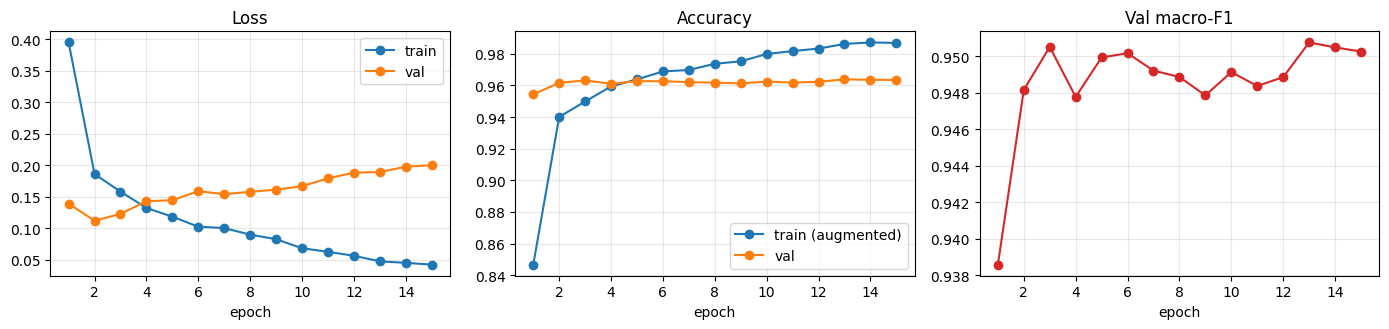

  ep  1 | train loss 0.3951 acc 0.8467 | val loss 0.1391 acc 0.9543 macro-F1 0.9386
  ep  2 | train loss 0.1861 acc 0.9400 | val loss 0.1120 acc 0.9616 macro-F1 0.9482
  ep  3 | train loss 0.1582 acc 0.9498 | val loss 0.1228 acc 0.9632 macro-F1 0.9505
  ep  4 | train loss 0.1323 acc 0.9593 | val loss 0.1430 acc 0.9610 macro-F1 0.9478
  ep  5 | train loss 0.1184 acc 0.9638 | val loss 0.1446 acc 0.9626 macro-F1 0.9499
  ep  6 | train loss 0.1025 acc 0.9688 | val loss 0.1589 acc 0.9626 macro-F1 0.9502
  ep  7 | train loss 0.1003 acc 0.9697 | val loss 0.1541 acc 0.9620 macro-F1 0.9492
  ep  8 | train loss 0.0899 acc 0.9737 | val loss 0.1579 acc 0.9617 macro-F1 0.9489
  ep  9 | train loss 0.0827 acc 0.9752 | val loss 0.1613 acc 0.9612 macro-F1 0.9479
  ep 10 | train loss 0.0683 acc 0.9798 | val loss 0.1668 acc 0.9624 macro-F1 0.9491
  ep 11 | train loss 0.0626 acc 0.9817 | val loss 0.1793 acc 0.9617 macro-F1 0.9484
  ep 12 | train loss 0.0564 acc 0.9832 | val loss 0.1883 acc 0.9623 macro-F1

In [6]:
class EMA:
    def __init__(self, net, decay):
        self.model = copy.deepcopy(net).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.decay, self.n = decay, 0

    @torch.no_grad()
    def update(self, net):
        self.n += 1
        d = min(self.decay, (1 + self.n) / (10 + self.n))      # faster at the start
        for e, m in zip(self.model.state_dict().values(), net.state_dict().values()):
            if e.dtype.is_floating_point:
                e.mul_(d).add_(m.detach(), alpha=1 - d)
            else:
                e.copy_(m)

opt = torch.optim.AdamW([{"params": model.backbone_params(), "lr": LR_BACKBONE},
                         {"params": model.head_params(), "lr": LR_HEAD}], weight_decay=WEIGHT_DECAY)
steps_per_epoch = len(train_loader)
total_steps, warm_steps = EPOCHS * steps_per_epoch, max(1, WARMUP_EPOCHS * steps_per_epoch)
def lr_lambda(step):
    if step < warm_steps:
        return (step + 1) / warm_steps
    prog = (step - warm_steps) / max(1, total_steps - warm_steps)
    return max(0.01, 0.5 * (1 + math.cos(math.pi * prog)))
sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
try:
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
except (AttributeError, TypeError):
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
ema = EMA(model, EMA_DECAY) if USE_EMA else None
eval_net = (lambda: ema.model) if USE_EMA else (lambda: model)

CFG = dict(run=RUN_NAME, model=MODEL, head=HEAD, seed=SEED, epochs=EPOCHS, lr_backbone=LR_BACKBONE, lr_head=LR_HEAD,
           weight_decay=WEIGHT_DECAY, warmup_epochs=WARMUP_EPOCHS, label_smoothing=LABEL_SMOOTHING, ema=USE_EMA,
           ema_decay=EMA_DECAY, grad_clip=GRAD_CLIP, pretrained=PRETRAINED, batch_size=BATCH_SIZE,
           samples_per_epoch=SAMPLES_PER_EPOCH, sampler=SAMPLER, img_size=IMG_SIZE, dim=DIM, depth=DEPTH, heads=HEADS,
           kl_weight=KL_WEIGHT, kl_anneal_epochs=KL_ANNEAL_EPOCHS, params_m=n_params, dataset=str(OUT_ROOT))
json.dump(CFG, open(OUT_DIR / "config.json", "w"), indent=2)

def plot_history(h):
    ep = range(1, len(h["val_f1"]) + 1)
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
    axs[0].plot(ep, h["train_loss"], "o-", label="train"); axs[0].plot(ep, h["val_loss"], "o-", label="val")
    axs[0].set_title("Loss"); axs[0].legend()
    axs[1].plot(ep, h["train_acc"], "o-", label="train (augmented)"); axs[1].plot(ep, h["val_acc"], "o-", label="val")
    axs[1].set_title("Accuracy"); axs[1].legend()
    axs[2].plot(ep, h["val_f1"], "o-", color="tab:red"); axs[2].set_title("Val macro-F1")
    for a in axs:
        a.set_xlabel("epoch"); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

history = collections.defaultdict(list)
best_f1, best_epoch, start_epoch, elapsed = -1.0, 0, 0, 0.0
if RESUME and LAST.exists():
    ck = torch.load(LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    if USE_EMA:
        ema.model.load_state_dict(ck["ema"]); ema.n = ck["ema_n"]
    history = collections.defaultdict(list, ck["history"])
    best_f1, best_epoch, start_epoch, elapsed = ck["best_f1"], ck["best_epoch"], ck["epoch"], ck["elapsed"]
    print(f"Resumed from epoch {start_epoch} (best val macro-F1 {best_f1:.4f} at epoch {best_epoch})")

t_session = time.time()
for epoch in range(start_epoch, EPOCHS):
    model.train()
    t0 = time.time()
    run_loss = run_correct = seen = 0
    for x, y in tqdm(train_loader, desc=f"epoch {epoch + 1}/{EPOCHS}", leave=False):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        loss = compute_loss(logits, y, epoch)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(opt)
        scaler.update()
        sched.step()
        if USE_EMA:
            ema.update(model)
        run_loss += loss.item() * len(y)
        run_correct += (logits.argmax(1) == y).sum().item()
        seen += len(y)

    val = evaluate(eval_net(), val_loader, epoch)
    for k, v in zip(("train_loss", "train_acc", "val_loss", "val_acc", "val_f1"),
                    (run_loss / seen, run_correct / seen, val["loss"], val["acc"], val["macro_f1"])):
        history[k].append(v)
    if val["macro_f1"] > best_f1:
        best_f1, best_epoch = val["macro_f1"], epoch + 1
        torch.save({"model": eval_net().state_dict(), "epoch": best_epoch, "cfg": CFG, "classes": CLASSES}, BEST)
    ck_out = {"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(), "scaler": scaler.state_dict(),
              "history": dict(history), "best_f1": best_f1, "best_epoch": best_epoch, "epoch": epoch + 1,
              "elapsed": elapsed + (time.time() - t_session) / 60}
    if USE_EMA:
        ck_out["ema"], ck_out["ema_n"] = ema.model.state_dict(), ema.n
    torch.save(ck_out, LAST)
    json.dump(dict(history), open(OUT_DIR / "history.json", "w"))

    clear_output(wait=True)
    print(f"[{RUN_NAME}] epoch {epoch + 1}/{EPOCHS} | {time.time() - t0:.0f}s | best val macro-F1 {best_f1:.4f} (epoch {best_epoch})")
    plot_history(history)
    for i in range(len(history["val_f1"])):
        print(f"  ep {i + 1:2d} | train loss {history['train_loss'][i]:.4f} acc {history['train_acc'][i]:.4f} "
              f"| val loss {history['val_loss'][i]:.4f} acc {history['val_acc'][i]:.4f} macro-F1 {history['val_f1'][i]:.4f}")

train_minutes = elapsed + (time.time() - t_session) / 60
print(f"\nTraining finished. Best val macro-F1 {best_f1:.4f} at epoch {best_epoch} | {train_minutes:.0f} min")

## 7. Final evaluation
Loads the best checkpoint and scores validation and **test** once. Reports accuracy, macro-F1 with 95% bootstrap intervals, per-class results,
calibration (ECE), and how well the uncertainty score flags errors (AUROC, referral curve).

In [7]:
final = build_model(False)
ck = torch.load(BEST, map_location=DEVICE, weights_only=False)
final.load_state_dict(ck["model"])
print(f"Loaded best checkpoint (epoch {ck['epoch']})")

val = evaluate(final, val_loader)
test = evaluate(final, test_loader)

def summarise(o):
    cor = o["pred"] == o["y"]
    prec, rec, f1 = prf(o["cm"])
    s = dict(n=len(o["y"]), acc=o["acc"], macro_f1=o["macro_f1"], ece=ece_score(o["probs"], o["y"]), errors=int((~cor).sum()),
             auroc=auroc(o["unc"][~cor], o["unc"][cor]) if (~cor).any() and cor.any() else None,
             unc_correct=float(o["unc"][cor].mean()), unc_wrong=float(o["unc"][~cor].mean()) if (~cor).any() else None,
             acc_at_90=acc_at_coverage(o["y"], o["pred"], o["unc"], 0.9), acc_at_80=acc_at_coverage(o["y"], o["pred"], o["unc"], 0.8),
             per_class={c: dict(precision=float(prec[i]), recall=float(rec[i]), f1=float(f1[i]), support=int(o["cm"][i].sum()))
                        for i, c in enumerate(CLASSES)},
             confusion_matrix=o["cm"].tolist())
    a_ci, f_ci = bootstrap_ci(o["y"], o["pred"], K)
    s["acc_ci95"], s["f1_ci95"] = [float(v) for v in a_ci], [float(v) for v in f_ci]
    return s

sv, st = summarise(val), summarise(test)
fmt = lambda v, nd=4: "n/a" if v is None else f"{v:.{nd}f}"
for name, s in (("VAL ", sv), ("TEST", st)):
    print(f"{name} | n {s['n']:,} | acc {s['acc'] * 100:.2f}% [{s['acc_ci95'][0] * 100:.2f}, {s['acc_ci95'][1] * 100:.2f}] | "
          f"macro-F1 {s['macro_f1']:.4f} [{s['f1_ci95'][0]:.4f}, {s['f1_ci95'][1]:.4f}] | ECE {s['ece']:.4f} | "
          f"errors {s['errors']} | AUROC(err) {fmt(s['auroc'], 3)}")
print("\nTEST per class:")
print("  " + "class".ljust(8) + "precision   recall      f1   support")
for c, d in st["per_class"].items():
    print(f"  {c:8s}{d['precision']:9.4f}{d['recall']:9.4f}{d['f1']:9.4f}{d['support']:9d}")
print(f"\nTEST uncertainty: mean {fmt(st['unc_correct'])} (correct) vs {fmt(st['unc_wrong'])} (wrong) | "
      f"acc keeping the 90% / 80% most certain: {st['acc_at_90'] * 100:.2f}% / {st['acc_at_80'] * 100:.2f}%")

Loaded best checkpoint (epoch 13)
VAL  | n 7,789 | acc 96.38% [95.97, 96.78] | macro-F1 0.9508 [0.9450, 0.9560] | ECE 0.0298 | errors 282 | AUROC(err) 0.887
TEST | n 7,734 | acc 93.69% [93.17, 94.19] | macro-F1 0.9207 [0.9140, 0.9273] | ECE 0.0511 | errors 488 | AUROC(err) 0.831

TEST per class:
  class   precision   recall      f1   support
  CNV        0.9743   0.9060   0.9389     3267
  DME        0.8387   0.9471   0.8896     1191
  DRUSEN     0.8378   0.9188   0.8765      776
  NORMAL     0.9780   0.9780   0.9780     2500

TEST uncertainty: mean 0.0070 (correct) vs 0.0871 (wrong) | acc keeping the 90% / 80% most certain: 96.98% / 97.88%


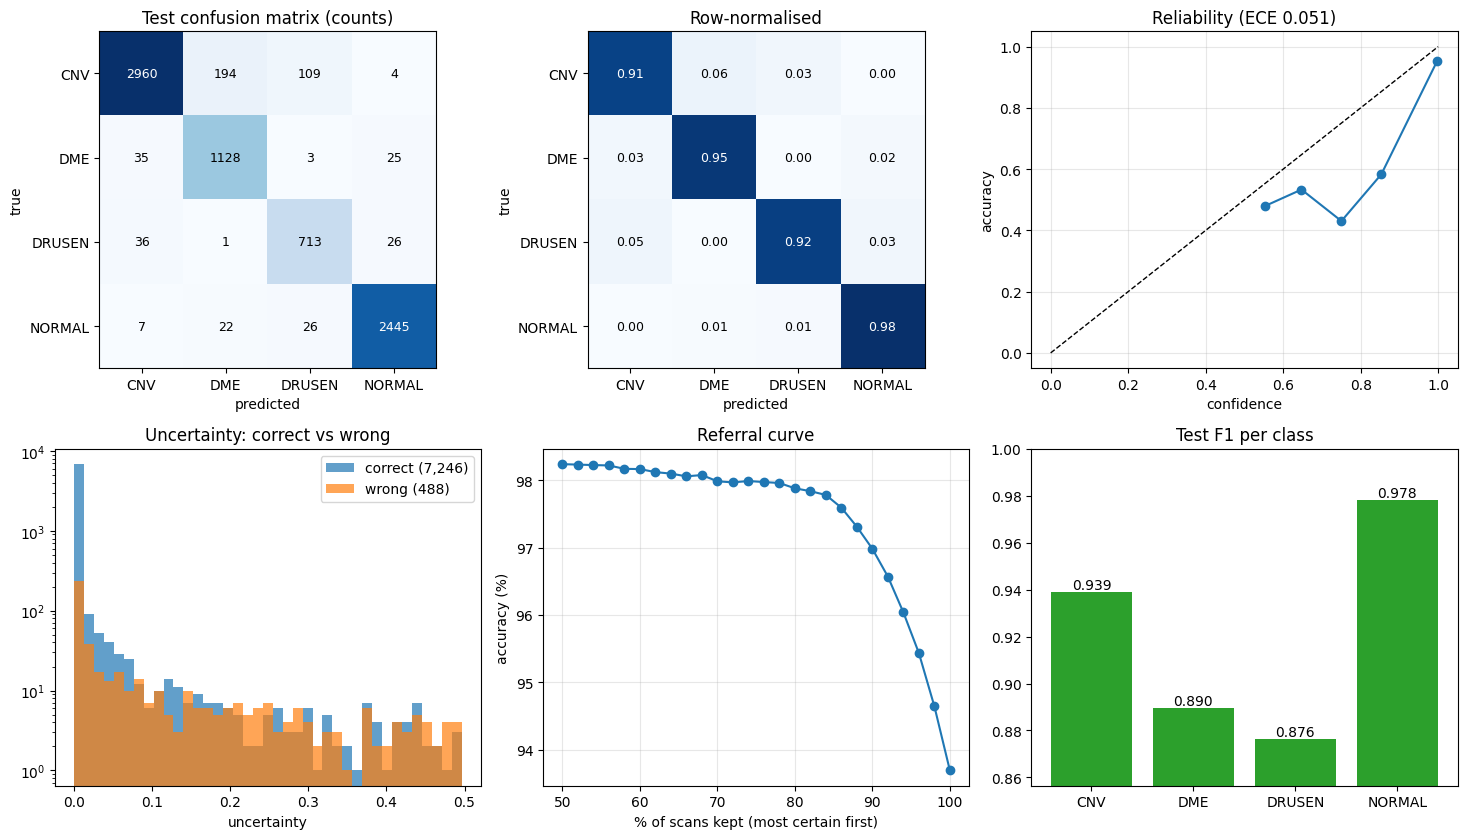

In [8]:
fig, axs = plt.subplots(2, 3, figsize=(15, 8.5))
cm = test["cm"]
for ax, mat, title, fm in ((axs[0, 0], cm, "Test confusion matrix (counts)", "d"), (axs[0, 1], cm / cm.sum(1, keepdims=True), "Row-normalised", ".2f")):
    ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(K)); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(K):
        for j in range(K):
            ax.text(j, i, format(mat[i, j], fm), ha="center", va="center", color="white" if mat[i, j] > mat.max() / 2 else "black", fontsize=9)

# reliability diagram
conf, cor = test["probs"].max(1), (test["pred"] == test["y"]).astype(float)
edges = np.linspace(0, 1, 11)
xs, ys, ns = [], [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (conf > lo) & (conf <= hi)
    if m.sum() >= 5:
        xs.append(conf[m].mean()); ys.append(cor[m].mean()); ns.append(m.sum())
axs[0, 2].plot([0, 1], [0, 1], "k--", lw=1); axs[0, 2].plot(xs, ys, "o-")
axs[0, 2].set_xlabel("confidence"); axs[0, 2].set_ylabel("accuracy"); axs[0, 2].set_title(f"Reliability (ECE {st['ece']:.3f})"); axs[0, 2].grid(alpha=0.3)

# uncertainty: correct vs wrong
okm = test["pred"] == test["y"]
bins = np.linspace(0, max(test["unc"].max(), 1e-6), 40)
axs[1, 0].hist(test["unc"][okm], bins=bins, alpha=0.7, label=f"correct ({okm.sum():,})")
if (~okm).any():
    axs[1, 0].hist(test["unc"][~okm], bins=bins, alpha=0.7, label=f"wrong ({(~okm).sum():,})")
axs[1, 0].set_yscale("log"); axs[1, 0].set_xlabel("uncertainty"); axs[1, 0].set_title("Uncertainty: correct vs wrong"); axs[1, 0].legend()

# referral curve
cov = np.linspace(0.5, 1.0, 26)
axs[1, 1].plot(cov * 100, [acc_at_coverage(test["y"], test["pred"], test["unc"], c) * 100 for c in cov], "o-")
axs[1, 1].set_xlabel("% of scans kept (most certain first)"); axs[1, 1].set_ylabel("accuracy (%)")
axs[1, 1].set_title("Referral curve"); axs[1, 1].grid(alpha=0.3)

# per-class F1
f1s = [st["per_class"][c]["f1"] for c in CLASSES]
b = axs[1, 2].bar(CLASSES, f1s, color="tab:green")
axs[1, 2].bar_label(b, fmt="%.3f"); axs[1, 2].set_ylim(min(0.9, min(f1s) - 0.02), 1.0); axs[1, 2].set_title("Test F1 per class")
plt.tight_layout()
plt.savefig(OUT_DIR / "evaluation.png", dpi=150)
plt.show()

In [9]:
paths = np.array([p for p, _ in ds_test.samples])
np.savez(OUT_DIR / "test_outputs.npz", y=test["y"], pred=test["pred"], unc=test["unc"], probs=test["probs"], paths=paths)
np.savez(OUT_DIR / "val_outputs.npz", y=val["y"], pred=val["pred"], unc=val["unc"], probs=val["probs"])
json.dump({"run": RUN_NAME, "cfg": CFG, "best_epoch": best_epoch, "best_val_f1": best_f1, "train_minutes": train_minutes,
           "val": sv, "test": st}, open(OUT_DIR / "metrics.json", "w"), indent=2)
print("Saved to", OUT_DIR.resolve())
print("  best.pt, last.pt, config.json, history.json, metrics.json, test_outputs.npz, val_outputs.npz, evaluation.png")

Saved to C:\Users\User\Desktop\NNDL-2\outputs\runs\cnn_softmax_s42
  best.pt, last.pt, config.json, history.json, metrics.json, test_outputs.npz, val_outputs.npz, evaluation.png


## What to do next
1. **Baseline done.** Note the test accuracy, macro-F1 and interval; this is the number every other variant has to beat.
2. Change two lines in section 1 and run again for each variant: `MODEL="ms", HEAD="softmax"`, then `MODEL="ms", HEAD="evidential"` (and optionally `MODEL="cnn", HEAD="evidential"`).
3. Repeat the variants you care about with `SEED = 43, 44` for mean +/- std.
4. **Notebook 04** loads every `outputs/runs/*/test_outputs.npz` and builds the comparison table, referral curves and Grad-CAM.